### Homework 6

#### Set up

In [106]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error
import xgboost as xgb
import matplotlib.pyplot as plt

df_raw = pd.read_csv('../00-data/car_fuel_efficiency_2026.csv')
df = df_raw.copy()

# Fill missing values with zeros
df.fillna(0, inplace=True)

# Split into train and test
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

# Reset index
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Set target
y_train = df_train['fuel_efficiency_mpg'].values
y_val = df_val['fuel_efficiency_mpg'].values
y_test = df_test['fuel_efficiency_mpg'].values

# Delete target from dataframe
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

# Turn dataframes into matrices
train_dicts = df_train.to_dict(orient='records')
dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(train_dicts)
val_dicts = df_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)
test_dicts = df_test.to_dict(orient='records')
X_test = dv.transform(test_dicts)

#### Question 1
Let's train a decision tree regressor to predict the fuel_efficiency_mpg variable.

Train a model with max_depth=1.
Which original feature is used for splitting the data? If you use DictVectorizer, map a one-hot feature such as origin=USA back to its original column name.

In [107]:
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",1
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with 

In [108]:
df.columns

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='str')

In [109]:
print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



In [110]:
print('RESPONSE: model_year')

RESPONSE: model_year


#### Question 2
Train a random forest regressor with these parameters:

- n_estimators=10
- random_state=1
- n_jobs=-1 (optional - to make training faster)

What's the RMSE of this model on the validation data?

In [111]:
rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_val)
rmse = root_mean_squared_error(y_val, y_pred)
print(f"RMSE: {round(rmse, 3)}")

RMSE: 1.833


#### Question 3
Now let's experiment with the n_estimators parameter

Try these values of this parameter: [10, 50, 100, 150].
Set random_state to 1.
Evaluate the model on the validation dataset.

Which value gives the lowest validation RMSE? Consider 3 decimal places for calculating the answer.

In [112]:
n_estimators=[10, 50, 100, 150]
random_state=1
n_jobs=-1
rmses = []

for n_estimator in n_estimators:
    rf = RandomForestRegressor(n_estimators=n_estimator, random_state=random_state, n_jobs=n_jobs)
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_val)
    rmse = root_mean_squared_error(y_val, y_pred)
    rmse = round(rmse, 3)
    rmses.append((n_estimator, rmse))
    
rmses = pd.DataFrame(rmses, columns=['n_estimator', 'rmse'])
rmses.sort_values('rmse', ascending=True)
    


,n_estimator,rmse
3,150,1.769
2,100,1.770
1,50,1.774
0,10,1.833


In [113]:
min_rmse_row = rmses.loc[rmses['rmse'].idxmin()]
print(f'RESPONSE: {min_rmse_row["n_estimator"]} with RMSE: {min_rmse_row["rmse"]}')

RESPONSE: 150.0 with RMSE: 1.769


#### Question 4
Let's select the best max_depth:

Try different values of max_depth: [10, 15, 20, 25]
For each of these values,
try different values of n_estimators from [10, 50, 100, 150]
calculate the mean RMSE
Fix the random seed: random_state=1

What's the best max_depth, using the mean RMSE?

In [114]:
max_depths = [10, 15, 20, 25]
n_estimators = [10, 50, 100, 150]
random_state = 1
n_jobs = -1
rmse_means = []

for max_depth in max_depths:
    rmses = []
    for n_estimator in n_estimators:
        rf = RandomForestRegressor(
            n_estimators=n_estimator,
            max_depth=max_depth,
            random_state=random_state,
            n_jobs=n_jobs,
        )
        rf.fit(X_train, y_train)
        y_pred = rf.predict(X_val)
        rmse = root_mean_squared_error(y_val, y_pred)
        rmses.append(rmse)
    rmse_mean = np.mean(rmses)
    rmse_mean = round(rmse_mean, 3)
    rmse_means.append((max_depth, rmse_mean))

rmse_means = pd.DataFrame(rmse_means, columns=['max_depth', 'rmse_mean'])
rmse_means

,max_depth,rmse_mean
0,10,1.754
1,15,1.784
2,20,1.787
3,25,1.786


In [115]:
min_rmse_mean_row = rmse_means.loc[rmse_means['rmse_mean'].idxmin()]
print(f'RESPONSE: {min_rmse_mean_row["max_depth"]} with RMSE: {min_rmse_mean_row["rmse_mean"]}')

RESPONSE: 10.0 with RMSE: 1.754


#### Question 5
We can extract feature importance information from tree-based models.

At each step of the decision tree learning algorithm, it finds the best split. When doing it, we can calculate "gain" - the reduction in impurity before and after the split. This gain is quite useful in understanding what are the important features for tree-based models.

In Scikit-Learn, tree-based models contain this information in the feature_importances_ field.

For this homework question, we'll find the most important feature:

Train the model with these parameters:
- n_estimators=10,
- max_depth=20,
- random_state=1,
- n_jobs=-1 (optional)

Get the feature importance information from this model
What's the most important feature?


In [116]:
rf = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)
df_importances = pd.DataFrame()
df_importances['feature'] = dv.get_feature_names_out()
df_importances['importance'] = rf.feature_importances_
df_importances = df_importances.sort_values(by='importance', ascending=False)
df_importances.head()

,feature,importance
9,model_year,0.296107
15,vehicle_weight,0.203313
6,fuel_type=Gasoline,0.160712
8,horsepower,0.078271
4,engine_displacement,0.061281


In [ ]:
print('RESPONSE: Most important feature among vehicle_weight, horsepower, acceleration, engine_displacement is vehicle_weight')

RESPONSE: Most important feature among  vehicle_weight, horsepower, acceleration, engine_displacement is vehicle_weight


### Question 6
Now let's train an XGBoost model! For this question, we'll tune the eta parameter:

- Install XGBoost
- Create DMatrix for train and validation
- Create a watchlist
- Train a model with these parameters for 100 rounds:

```python
xgb_params = {
    'eta': 0.3, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}
```

Now change eta from 0.3 to 0.1.

Which eta leads to the best RMSE score on the validation dataset?

In [130]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)
watchlist = [(dtrain, 'train'), (dval, 'val')]
scores = {}

In [131]:
def parse_xgb_output(output):
    results = []
    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')
        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])
        results.append((it, train, val))
    columns = ['num_iter', 'train_rmse', 'val_rmse']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

In [132]:
%%capture output03

xgb_params = {
    'eta': 0.3, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=100, verbose_eval=5, evals=watchlist)

scores["eta=0.3"] = parse_xgb_output(output03)

In [133]:
%%capture output01

xgb_params = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=100, verbose_eval=5, evals=watchlist)

scores["eta=0.1"] = parse_xgb_output(output01)

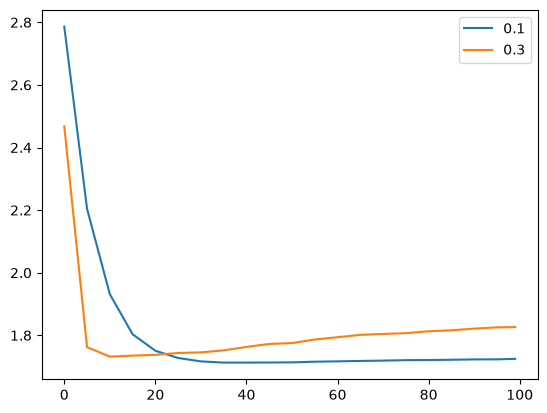

In [135]:
plt.plot(scores['eta=0.1'].num_iter, scores['eta=0.1'].val_rmse,
        label='0.1')
plt.plot(scores['eta=0.3'].num_iter, scores['eta=0.3'].val_rmse,
        label='0.3')
plt.legend()
plt.show()

In [136]:
print('RESPONSE: ETA with best RMSE score on the validation dataset: 0.1')

RESPONSE: ETA with best RMSE score on the validation dataset: 0.1
